# 01 · 데이터 준비와 공시 확률 검증 — 간소화 최종본
**실행 코드 5셀**. 기존 82셀의 반복 탐색·복구·중복 출력·사용하지 않는 파생변수 계산을 제거했습니다.

이 노트북은 **이미 저장된 정제 데이터에서 시작**합니다. 최초 ZIP 결합/암호 해제/CSV 번역 작업은 완료된 전처리 이력으로 남기고 재실행하지 않습니다.
`genshin_analysis_ready.parquet`를 우선 사용하며, 없으면 기존 clean/analysis Parquet 또는 `pulls_parquet/part-*.parquet`에서 복원합니다.
이들까지 없으면 최초 CSV 전처리가 필요하다는 오류로 중단합니다. 인터넷에서 임의의 새 데이터를 받아 실험 자료를 바꾸지 않습니다.

- 사용자별 70/15/15 분할과 약 10만 행의 기존 학습 표본을 유지합니다.
- 검증/테스트 원본은 전체 사용자를 유지하고, 이미 저장되어 있으면 재추출하지 않습니다.
- 확률 검증에는 전체 원본을 사용하며 모델 학습 라벨을 섞지 않습니다.
- 사용자 단위 부트스트랩 95% CI를 주 분석으로, Wilson CI·이항검정/Holm을 참고 분석으로 저장합니다.

**현재 모델 완성이 급하고 기존 저장 파일이 모두 있다면 02번부터 바로 실행해도 됩니다.**
논문용 공시 확률 표·그림이 필요할 때 01번을 실행하세요.

## 실행 전
1. **런타임 → 런타임 유형 변경 → CPU**를 선택합니다. GPU는 필요하지 않습니다.
2. 기존의 긴 노트북 런타임은 **연결 해제 및 삭제**하고, 이 노트북을 새 런타임에서 실행합니다.
3. 첫 셀의 `BASE`는 기존 Google Drive 경로입니다. 폴더를 옮겼다면 이 한 곳만 바꿉니다.
4. 위에서 아래로 실행합니다. 빨간 오류가 나오면 중단하고 그 오류를 확인합니다. 오류를 무시하고 아래 셀을 실행하지 않습니다.
5. 실행 결과는 Drive의 `capstonedata2/capstone_final_v2/`에 저장됩니다. 기존 원본·기존 모델 파일은 덮어쓰지 않습니다.

서버 RAM 사용을 줄이기 위해 65,536행씩 읽고, 모델은 CPU 2개와 희소 인코딩을 사용합니다.
브라우저에는 짧은 표와 정적 그림만 출력합니다. Colab 연산은 원격 서버에서 수행되며, 이 최적화가 노트북 화면 깜빡임의 하드웨어/브라우저 원인까지 해결한다고 보장하지는 않습니다.
40분 내 완료를 목표로 구성했지만 Drive 속도·런타임에 따라 달라집니다. 대규모 탐색/교차검증은 수행하지 않습니다.


## 1. 환경·경로 설정
Drive 연결을 허용합니다. 기존 데이터 파일을 삭제하지 않습니다.

In [1]:
# CPU 일반 런타임에서 실행. 새 런타임에서 위에서 아래로 실행하세요.
import os
for key in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMEXPR_NUM_THREADS']:
    os.environ[key] = '2'
import importlib.util, subprocess, sys
packages = {'pyarrow':'pyarrow', 'sklearn':'scikit-learn', 'scipy':'scipy',
            'pandas':'pandas', 'numpy':'numpy', 'matplotlib':'matplotlib', 'joblib':'joblib'}
missing = [v for k,v in packages.items() if importlib.util.find_spec(k) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
from pathlib import Path
if not Path('/content/drive/MyDrive').exists():
    from google.colab import drive
    drive.mount('/content/drive')
import json, gc, time, hashlib, shutil, platform
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
BASE = Path('/content/drive/MyDrive/캡스톤 2/capstonedata2')
PROCESSED = BASE / 'genshin_processed'
DATA = BASE / 'rf_model_data'
OUT = BASE / 'capstone_final_v2'
OUT.mkdir(parents=True, exist_ok=True)
BATCH = 65536
SEED = 42
BANNER = {'100':'beginner', '200':'standard', '301':'character_event',
          '302':'weapon_event', '400':'character_event'}
KEY = ['user_id', 'gacha_id']
RAW = KEY + ['name_zh','name_ko','gacha_type','item_type','rank_type','gacha_time']

def save_json(obj, path):
    tmp = Path(str(path)+'.tmp')
    tmp.write_text(json.dumps(obj, ensure_ascii=False, indent=2, default=str), encoding='utf-8')
    os.replace(tmp, path)

def fingerprint(path):
    p = Path(path)
    return {'path':str(p), 'bytes':p.stat().st_size, 'mtime_ns':p.stat().st_mtime_ns}

def canonical(df):
    df = df.copy()
    for c in KEY:
        assert df[c].notna().all(), f'{c} 결측'
        df[c] = df[c].astype(str).str.strip()
        assert df[c].ne('').all(), f'{c} 빈 값'
    df['gacha_type'] = pd.to_numeric(df['gacha_type'], errors='raise').astype('int16').astype(str)
    for c in ['item_type','rank_type']:
        df[c] = pd.to_numeric(df[c], errors='raise').astype('int8')
    df['gacha_time'] = pd.to_datetime(df['gacha_time'], errors='raise')
    for c in ['name_zh','name_ko']:
        df[c] = df[c].astype('string')
    assert df[RAW].notna().all().all(), '원본 필수 열 결측'
    assert df['gacha_type'].isin(BANNER).all(), '알 수 없는 배너'
    assert df['item_type'].isin([0,1]).all() and df['rank_type'].isin([3,4,5]).all()
    return df

print('준비 완료 | 묶음 크기:', BATCH, '| 결과 폴더:', OUT)


Mounted at /content/drive
준비 완료 | 묶음 크기: 65536 | 결과 폴더: /content/drive/MyDrive/캡스톤 2/capstonedata2/capstone_final_v2


## 2. 저장 데이터 재사용·전체 집계
첫 실행만 전체 자료를 순회합니다. 파일이 바뀌지 않으면 집계 캐시를 재사용합니다.

In [2]:
# 기존 최종 Parquet를 재사용. 압축 해제와 번역 다운로드는 반복하지 않습니다.
SOURCE = PROCESSED / 'genshin_analysis_ready.parquet'
if not SOURCE.exists():
    candidates = [PROCESSED/'genshin_analysis_clean.parquet', PROCESSED/'genshin_analysis.parquet']
    sources = [next((p for p in candidates if p.exists()), None)]
    if sources[0] is None:
        sources = sorted((PROCESSED/'pulls_parquet').glob('part-*.parquet'))
    assert sources, '기존 정제 Parquet가 없습니다. 원본 노트북의 최초 CSV 전처리가 필요합니다.'
    tmp = SOURCE.with_suffix('.building')
    writer = None
    try:
        for source in sources:
            for batch in pq.ParquetFile(source).iter_batches(batch_size=BATCH, columns=RAW):
                d = canonical(batch.to_pandas())
                t = pa.Table.from_pandas(d[RAW], preserve_index=False)
                if writer is None: writer = pq.ParquetWriter(tmp, t.schema, compression='zstd')
                writer.write_table(t)
        assert writer is not None
        writer.close(); writer = None
        os.replace(tmp, SOURCE)
    finally:
        if writer: writer.close()
assert set(RAW).issubset(pq.ParquetFile(SOURCE).schema_arrow.names)
print('재사용 원본:', SOURCE.name, '| 기록:', f'{pq.ParquetFile(SOURCE).metadata.num_rows:,}')

# 전체 데이터를 RAM에 올리지 않고 사용자·배너별 작은 집계표만 유지합니다.
AGG = OUT/'user_banner_counts.parquet'
META = OUT/'aggregate_source.json'
sig = fingerprint(SOURCE)
if AGG.exists() and META.exists() and json.loads(META.read_text()) == sig:
    counts = pd.read_parquet(AGG)
else:
    accum = {}
    for i,b in enumerate(pq.ParquetFile(SOURCE).iter_batches(batch_size=BATCH, columns=['user_id','gacha_type','rank_type'])):
        d = b.to_pandas()
        d['user_id'] = d['user_id'].astype(str).str.strip()
        d['banner_group'] = pd.to_numeric(d['gacha_type']).astype(int).astype(str).map(BANNER)
        assert d['banner_group'].notna().all()
        d['fives'] = pd.to_numeric(d['rank_type']).eq(5).astype('int8')
        a = d.groupby(['user_id','banner_group'])['fives'].agg(['size','sum'])
        for k,r in a.iterrows():
            old = accum.get(k, (0,0)); accum[k] = (old[0]+int(r['size']),old[1]+int(r['sum']))
        if (i+1)%50 == 0: print('집계 처리:', f'{(i+1)*BATCH:,}', '행')
    counts = pd.DataFrame([(u,b,n,k) for (u,b),(n,k) in accum.items()],
                          columns=['user_id','banner_group','pulls','fives'])
    counts.to_parquet(AGG,index=False); save_json(sig,META)
    del accum; gc.collect()
assert counts['pulls'].sum() == pq.ParquetFile(SOURCE).metadata.num_rows
print('전체 사용자:', counts['user_id'].nunique())


재사용 원본: genshin_analysis_ready.parquet | 기록: 15,598,804
집계 처리: 3,276,800 행
집계 처리: 6,553,600 행
집계 처리: 9,830,400 행
집계 처리: 13,107,200 행
전체 사용자: 16289


## 3. 사용자 분할·모델용 파일 준비
기존 split과 학습 표본을 유지하고, 빠진 검증/테스트 원본만 묶음 저장합니다.

In [3]:
from sklearn.model_selection import train_test_split
split_path = DATA/'rf_split_users.csv'
DATA.mkdir(parents=True, exist_ok=True)
if split_path.exists():
    split = pd.read_csv(split_path,dtype={'user_id':str})
else:
    users = sorted(counts['user_id'].unique())
    tr, other = train_test_split(users,test_size=.30,random_state=SEED)
    va, te = train_test_split(other,test_size=.50,random_state=SEED)
    split = pd.DataFrame([(u,s) for s,us in [('train',tr),('val',va),('test',te)] for u in us],columns=['user_id','split'])
    split.to_csv(split_path,index=False,encoding='utf-8-sig')
assert not split['user_id'].duplicated().any()
assert set(split['split']) == {'train','val','test'}
assert set(split['user_id']) == set(counts['user_id'])
sets = {s:set(split.loc[split['split'].eq(s),'user_id']) for s in ['train','val','test']}
assert sets['train'].isdisjoint(sets['val']) and sets['train'].isdisjoint(sets['test']) and sets['val'].isdisjoint(sets['test'])
normal_path = DATA/'rf_normal_candidates.parquet'
if normal_path.exists():
    normal = canonical(pd.read_parquet(normal_path,columns=RAW))
    assert not normal.duplicated(KEY).any()
    assert set(normal['user_id']).issubset(sets['train'])
    selected = set(normal['user_id'])
    del normal
else:
    n = counts.groupby('user_id')['pulls'].sum()
    selected,total = set(),0
    for u in np.random.default_rng(SEED).permutation(sorted(sets['train'])):
        if total+int(n[u])<=100000:
            selected.add(u);total+=int(n[u])
    assert selected
paths = {'train':normal_path,'val':DATA/'rf_validation_raw.parquet','test':DATA/'rf_test_raw.parquet'}
needed = {s:p for s,p in paths.items() if not p.exists()}
writers = {}
try:
    if needed:
        for b in pq.ParquetFile(SOURCE).iter_batches(batch_size=BATCH,columns=RAW):
            d = canonical(b.to_pandas())
            for s,p in needed.items():
                part = d.loc[d['user_id'].isin(selected if s=='train' else sets[s]),RAW]
                if part.empty: continue
                t = pa.Table.from_pandas(part,preserve_index=False)
                if s not in writers: writers[s] = pq.ParquetWriter(str(p)+'.building',t.schema,compression='zstd')
                writers[s].write_table(t)
        for s,w in writers.items(): w.close()
        writers = {}
        for p in needed.values(): os.replace(str(p)+'.building',p)
finally:
    for w in writers.values(): w.close()
summary=[]
for s,p in paths.items():
    expected = int(counts.loc[counts['user_id'].isin(selected if s=='train' else sets[s]),'pulls'].sum())
    actual = pq.ParquetFile(p).metadata.num_rows
    assert expected==actual, f'{s}: 저장 행 수 불일치'
    summary.append({'split':s,'users':len(selected if s=='train' else sets[s]),'rows':actual})
pd.DataFrame(summary).to_csv(OUT/'dataset_summary.csv',index=False,encoding='utf-8-sig')
display(pd.DataFrame(summary))
print('02번 노트북 실행에 필요한 파일 준비 완료')


,split,users,rows
0,train,116,99998
1,val,2443,2411948
2,test,2444,2436782


02번 노트북 실행에 필요한 파일 준비 완료


## 4. 공시 확률 검증
사용자 군집 부트스트랩 1,000회. 단순 이항검정은 독립 시행 가정의 참고 결과입니다.

In [4]:
from scipy.stats import binomtest, norm
# 제출받은 기존 코드의 2021~2022년 비교 기준을 유지합니다.
# 논문 제출 시 해당 기간의 공식 기원 상세 화면/보관본을 별도로 인용하세요.
# 아래 수치는 이번 작업에서 공식 웹페이지로 재검증한 값이 아닙니다.
RATES = {'character_event':.016,'weapon_event':.0185,'standard':.016}
BOOTSTRAPS = 1000
rng = np.random.default_rng(SEED)
banners = list(RATES)
u = sorted(counts['user_id'].unique())
nmat = counts.pivot(index='user_id',columns='banner_group',values='pulls').reindex(index=u,columns=banners).fillna(0).to_numpy()
kmat = counts.pivot(index='user_id',columns='banner_group',values='fives').reindex(index=u,columns=banners).fillna(0).to_numpy()
boot = np.empty((BOOTSTRAPS,len(banners)))
for i in range(BOOTSTRAPS):
    ix = rng.integers(len(u),size=len(u)); den=nmat[ix].sum(axis=0)
    boot[i] = np.divide(kmat[ix].sum(axis=0),den,out=np.full(len(banners),np.nan),where=den>0)
rows=[]; z=norm.ppf(.975)
for j,b in enumerate(banners):
    n,k=int(nmat[:,j].sum()),int(kmat[:,j].sum());p=k/n
    center=(p+z*z/(2*n))/(1+z*z/n)
    half=z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/(1+z*z/n)
    low,high=np.nanpercentile(boot[:,j],[2.5,97.5])
    rows.append(dict(banner=b,pulls=n,fives=k,reference_rate=RATES[b],observed_rate=p,
        difference_percentage_points=100*(p-RATES[b]),wilson_low=center-half,wilson_high=center+half,
        user_bootstrap_low=low,user_bootstrap_high=high,
        reference_in_user_ci=bool(low<=RATES[b]<=high),binomial_p=binomtest(k,n,RATES[b]).pvalue))
stats=pd.DataFrame(rows)
order=np.argsort(stats['binomial_p'].to_numpy()); adjusted=np.empty(len(order))
adjusted[order]=np.minimum(1,np.maximum.accumulate(stats['binomial_p'].to_numpy()[order]*(len(order)-np.arange(len(order)))))
stats['holm_p']=adjusted
stats.to_csv(OUT/'probability_results.csv',index=False,encoding='utf-8-sig')
display(stats)
print('주 분석: 사용자 단위 95% CI. Wilson CI·이항검정은 독립 시행 가정의 참고 분석입니다.')
print('관측 차이는 확률 조작의 증거가 아니며, 수집·선택 편향과 천장 구조를 고려해야 합니다.')


,banner,pulls,fives,reference_rate,observed_rate,difference_percentage_points,wilson_low,wilson_high,user_bootstrap_low,user_bootstrap_high,reference_in_user_ci,binomial_p,holm_p
0,character_event,10310849,168055,0.0160,0.016299,0.029885,0.016222,0.016376,0.016264,0.016334,False,2.423985e-14,4.847970e-14
1,weapon_event,2839412,52821,0.0185,0.018603,0.010280,0.018446,0.018761,0.018535,0.018668,False,1.984464e-01,1.984464e-01
2,standard,2336423,35639,0.0160,0.015254,-0.074634,0.015097,0.015412,0.015170,0.015336,False,5.256789e-20,1.577037e-19


주 분석: 사용자 단위 95% CI. Wilson CI·이항검정은 독립 시행 가정의 참고 분석입니다.
관측 차이는 확률 조작의 증거가 아니며, 수집·선택 편향과 천장 구조를 고려해야 합니다.


## 5. 그림·실험 정보 저장
출력 확인 후 02번으로 이동합니다.

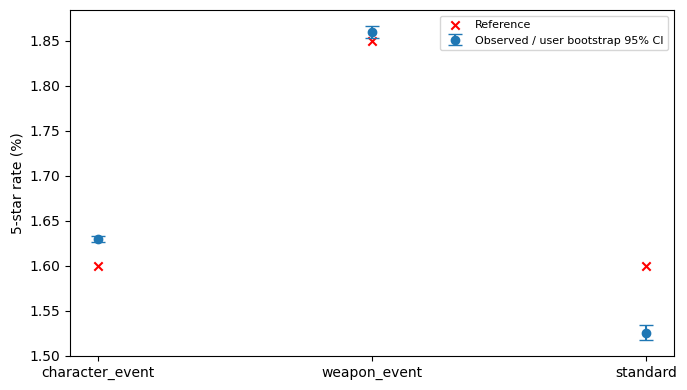

01 완료. 이 런타임의 연결을 해제하고 02번 노트북을 CPU 런타임에서 실행하세요.


In [5]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(7,4))
x=np.arange(len(stats)); p=stats['observed_rate'].to_numpy()*100
ax.errorbar(x,p,yerr=[p-stats['user_bootstrap_low'].to_numpy()*100,stats['user_bootstrap_high'].to_numpy()*100-p],fmt='o',capsize=5,label='Observed / user bootstrap 95% CI')
ax.scatter(x,stats['reference_rate']*100,marker='x',color='red',label='Reference')
ax.set_xticks(x,stats['banner']);ax.set_ylabel('5-star rate (%)');ax.legend(fontsize=8)
fig.tight_layout();fig.savefig(OUT/'probability_comparison.png',dpi=180);plt.show();plt.close(fig)
save_json({'source':fingerprint(SOURCE),'split':fingerprint(split_path),'batch_rows':BATCH,
           'probability_bootstraps':BOOTSTRAPS,'seed':SEED,'scope':'cached cleaned source; statistical analysis; model handoff',
           'limitations':['원본 CSV 최초 수집은 기존 처리 결과를 재사용','공식 확률 기준은 제공된 기존 코드에서 승계','통계적 차이는 조작 입증이 아님']},OUT/'preprocessing_manifest.json')
del counts,nmat,kmat,boot;gc.collect()
print('01 완료. 이 런타임의 연결을 해제하고 02번 노트북을 CPU 런타임에서 실행하세요.')


## 검증 범위와 제출 시 주의
이 파일은 코드 문법·노트북 형식 검사와 작은 합성 자료의 전체 실행 시험을 통과한 구성입니다.
첨부물에는 실제 Parquet 데이터가 없어 실제 데이터의 학습·성능 측정은 실행하지 않았습니다. 저장된 셀 출력은 모두 비워 두었습니다.
**논문에는 본인 Colab에서 생성된 수치만 사용하세요.**

원본 노트북의 실행 결과에서 학습 시간차 결측 383건은 사용자+배너 기준과 일치했고, 검증은 사용자 기준으로 2,443건이었습니다. 이를 동일 함수로 교정하고 재학습합니다.
공시 확률 1.60% / 1.85% / 1.60%는 제공된 기존 코드의 2021~2022년 비교 기준을 승계한 값입니다. 이번에 공식 자료를 새로 검증한 값은 아니므로 논문에 당시 공식 상세 화면/보관 자료를 인용해야 합니다.

최초 제출 계획서와의 관계: 이번 결과는 전처리·통계 분석·합성 변조 탐지·성능 평가에 해당합니다.
계획서의 웹 대시보드, 지출 시뮬레이션, 레코드 해시 기반 무결성 검사는 구현 완료로 주장하지 않습니다.
단일 시드 결과이며, 사용자 부트스트랩 CI는 모델 재학습 변동성이나 실제 공격의 다양성을 반영하지 않습니다.
오탐이 0인 표본에서 부트스트랩 FPR 구간이 0으로 나오더라도 실제 오탐 위험이 0이라는 뜻은 아닙니다.
